# Predicting Penguin Species with Machine Learning

## 1. Objective

**What does the model predict?**
The species of a penguin (**Adelie**, **Chinstrap**, or **Gentoo**) from four physical measurements: bill length, bill depth, flipper length, and body mass.

**Why is it useful?**
Researchers studying penguins in Antarctica often need to identify species quickly in the field. A model like this can identify species from simple measurements without genetic testing, which saves time and cost, and could help monitor population changes.

**Dataset:** Palmer Penguins (collected by Dr. Kristen Gorman at Palmer Station, Antarctica), loaded through `seaborn`.

**Models compared:** Decision Tree and K-Nearest Neighbors (KNN).

## 2. Data Preparation

### 2.1 Import libraries

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

### 2.2 Load the dataset

In [15]:
df = sns.load_dataset("penguins")
print("Shape:", df.shape)
df.head()

Shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


### 2.3 Check for missing values

In [17]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nRows with at least one missing value:", df.isnull().any(axis=1).sum())

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Rows with at least one missing value: 11


A few rows have missing values. Two rows are missing all four measurements, so they cannot be used. The `sex` column also has some gaps, but we will not use it as a feature. The simplest honest fix is to **drop the rows with missing measurements**, since we have plenty of data left.

In [18]:
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
target = "species"

df_clean = df.dropna(subset=features + [target]).reset_index(drop=True)
print("Rows before:", len(df), "| Rows after:", len(df_clean))
print("Remaining missing values in features:", df_clean[features].isnull().sum().sum())

Rows before: 344 | Rows after: 342
Remaining missing values in features: 0


### 2.4 Quick look at the data

species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


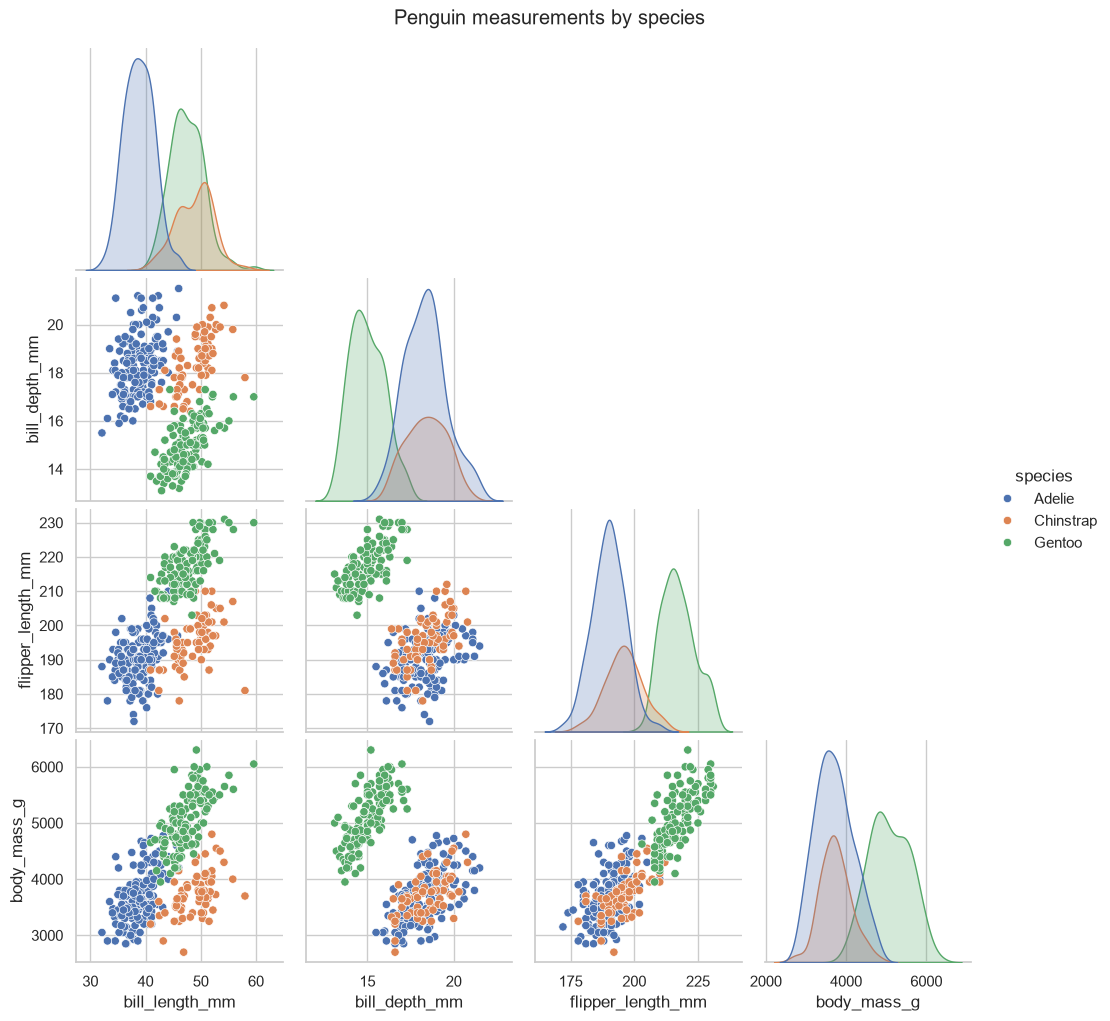

In [19]:
print(df_clean[target].value_counts())

sns.pairplot(df_clean, vars=features, hue=target, corner=True)
plt.suptitle("Penguin measurements by species", y=1.02)
plt.show()

The species form fairly distinct clusters, especially **Gentoo** (larger flippers and body mass). Adelie and Chinstrap overlap more, so that is where the models will most likely make mistakes.

### 2.5 Split features and target, then train/test split

In [20]:
X = df_clean[features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples: ", X_test.shape[0])

Training samples: 273
Testing samples:  69


`stratify=y` keeps the species proportions the same in the train and test sets.

**Scaling:** KNN is distance-based, so features with large values (body mass in grams) would dominate features with small values (bill depth in mm). We scale features for KNN. Decision Trees are not affected by scale, so they use the raw features.

## 3. Model Building

In [21]:
# Model 1: Decision Tree
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

# Model 2: KNN (with scaling inside a pipeline, so the scaler is fit on training data only)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)

print("Both models trained.")

Both models trained.


## 4. Evaluation

In [22]:
tree_pred = tree.predict(X_test)
knn_pred = knn.predict(X_test)

tree_acc = accuracy_score(y_test, tree_pred)
knn_acc = accuracy_score(y_test, knn_pred)

results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN (k=5)"],
    "Test Accuracy": [tree_acc, knn_acc]
})
results

,Model,Test Accuracy
0,Decision Tree,1.0
1,KNN (k=5),1.0


In [23]:
print("=== Decision Tree ===")
print(classification_report(y_test, tree_pred))
print("=== KNN ===")
print(classification_report(y_test, knn_pred))

=== Decision Tree ===
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69

=== KNN ===
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



### Confusion matrices

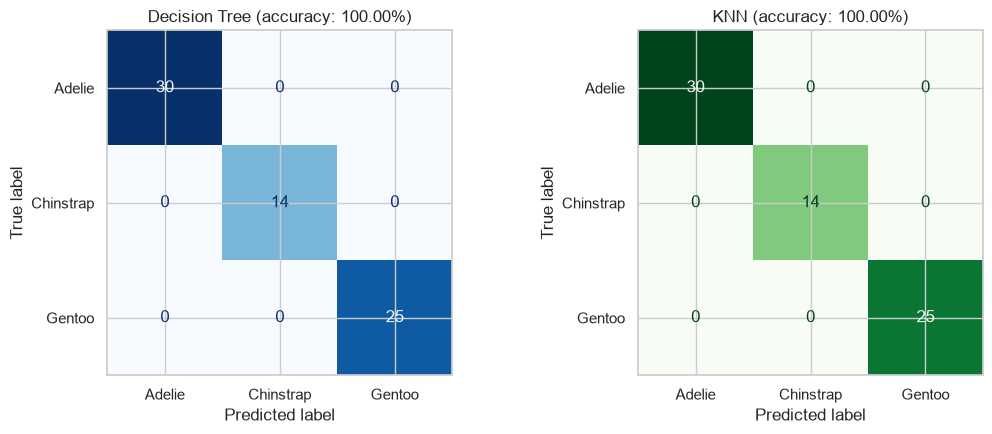

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, tree_pred, ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title(f"Decision Tree (accuracy: {tree_acc:.2%})")

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_pred, ax=axes[1], cmap="Greens", colorbar=False
)
axes[1].set_title(f"KNN (accuracy: {knn_acc:.2%})")

plt.tight_layout()
plt.show()

Cross-validation

With only 69 test samples, accuracy on a single split can swing by a few percent depending on the random split. Cross-validation gives a more reliable comparison by averaging over 5 different splits.

In [25]:
tree_cv = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=42), X, y, cv=5)
knn_cv = cross_val_score(
    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), X, y, cv=5
)

print(f"Decision Tree 5-fold CV accuracy: {tree_cv.mean():.2%} (+/- {tree_cv.std():.2%})")
print(f"KNN           5-fold CV accuracy: {knn_cv.mean():.2%} (+/- {knn_cv.std():.2%})")

Decision Tree 5-fold CV accuracy: 96.48% (+/- 1.51%)
KNN           5-fold CV accuracy: 98.83% (+/- 0.58%)


Decision Tree

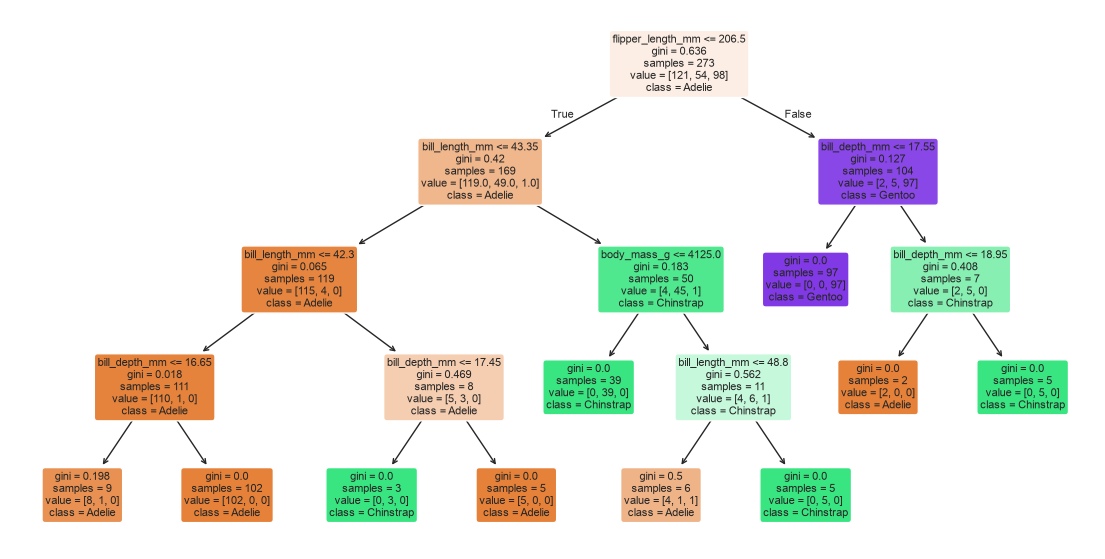

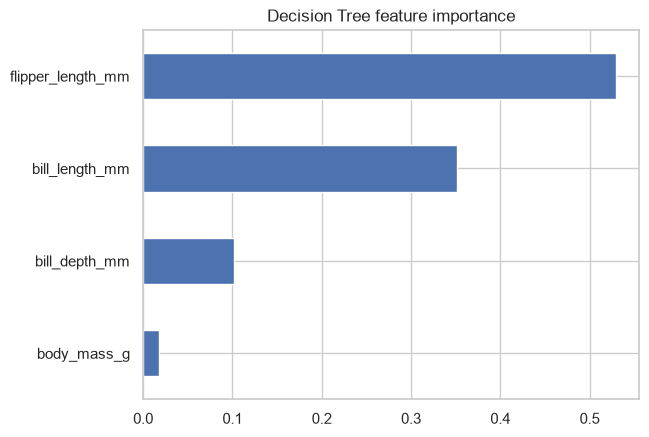

In [26]:
plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=features, class_names=tree.classes_, filled=True, rounded=True, fontsize=8)
plt.show()

pd.Series(tree.feature_importances_, index=features).sort_values().plot(kind="barh", title="Decision Tree feature importance")
plt.show()

## 5. Conclusion


1. Which model performed better?
 On the test set, both models scored 100% (69 of 69 correct), so the single split could not tell them apart.
 In 5-fold cross-validation, KNN averaged 98.83% (+/- 0.58%) and the Decision Tree averaged 96.48% (+/- 1.51%). So KNN performed slightly better and was also more stable across folds, though both models work very well for this problem.
2. Where did the errors happen?
 There were no errors on the test set: every confusion matrix entry sits on the diagonal. The small gap in cross-validation means a few penguins were misclassified in other splits, most likely Adelie and Chinstrap, which overlap in the pairplot. Gentoo is clearly separated by flipper length and body mass
3. Conclusion:
   Real datasets have missing values, and checking for them is a necessary first step.
   KNN needs feature scaling because it relies on distances; Decision Trees do not.
   Decision Trees are easy to interpret (we can see which features matter), while KNN is simple but slower on large data.
   A single train/test split on a small dataset can be misleading, so cross-validation gives a fairer comparison.
   Both models perform well because the species are quite separable by physical measurements.